<a href="https://colab.research.google.com/github/saraal1/IT326_Project/blob/main/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Problem

Heart disease remains a major healthcare concern worldwide because its symptoms and risk factors may not always be recognized early. Some individuals may have heart disease without clear warning signs, making early identification challenging.

Delayed detection can increase the risk of serious complications and reduce opportunities for timely medical intervention. It can also lead to more complex treatments and greater pressure on healthcare resources. Therefore, understanding the factors associated with heart disease is important for improving knowledge about this condition.

This project aims to analyze heart disease data using data mining techniques to classify patients according to the presence or absence of heart disease and identify groups of patients with similar characteristics. By exploring patterns in the dataset, the project seeks to understand how patient attributes relate to heart disease and demonstrate how classification and clustering can support data analysis in healthcare research.

#2. Data Mining Task

This project explores heart disease data through two complementary data mining tasks: classification and clustering. Each task examines the data from a different perspective to better understand the characteristics of patients and the patterns associated with heart disease.

Classification focuses on assigning each patient to the appropriate category according to their heart disease status. It uses patient information, including demographic characteristics and medical measurements, to distinguish between individuals with heart disease and those without it.

In contrast, clustering investigates the similarities between patients and organizes them into groups with comparable health characteristics, without using the heart disease status to determine group membership. This makes it possible to explore the structure of the data and identify patient groups that share common characteristics.

By combining classification and clustering, the project examines both the relationship between patient attributes and heart disease status and the similarities that exist among patients. Together, these tasks provide a more comprehensive view of the dataset and help uncover useful patterns for further analysis.

#3. Data

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/saraal1/IT326_Project/main/Dataset/Raw_dataset.csv"
df = pd.read_csv(url)

print("Raw Dataset:")
print(df.head())

print("\nNumber of objects:", df.shape[0])
print("Number of Attributes:", df.shape[1])

print("\nAttribute Information:")
print(df.info())

print("\nData Types:")
print(df.dtypes)

print("\nTarget Class Distribution:")
print(df["HeartDisease"].value_counts())

Raw Dataset:
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  

Number of objects: 918
Number of Attributes: 12

Attribute Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column     

The Heart Disease dataset contains **918 records and 12 attributes**, including 11 input features and one target variable (HeartDisease). The dataset includes patient information such as Age, Sex, ChestPainType, RestingBP, Cholesterol, FastingBS, RestingECG, MaxHR, ExerciseAngina, Oldpeak, and ST_Slope.

The attributes include both numerical and categorical data. The target variable, HeartDisease,  is binary  used for classification, where **0 indicates no heart disease and 1 indicates heart disease**. The dataset contains **508 records with heart disease and 410 records without heart disease**.

In Phase 1, we selected the Heart Disease dataset and explored its attributes, data types, and target variable.

In Phase 2, we applied data preprocessing techniques, including Z-score for noise removal, Chi-Square for feature selection, LabelEncoder for categorical data transformation, and MinMaxScaler for normalization.

#4. Data Preprocessing

In [ ]:

import numpy as np
import pandas as pd
from scipy.stats import zscore, chi2_contingency
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# =========================
# Noise Removal - Z-score
# =========================

# Snapshot of the raw dataset
print("Raw Dataset:")
print(df.head())

# Keep a copy of the raw dataset unchanged
Preprocessed_dataset = df.copy()

# Specify the numeric attributes for outlier analysis
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

# Calculate absolute Z-scores
z_scores = np.abs(zscore(Preprocessed_dataset[num_cols]))

# Set threshold to 3.0
threshold = 3.0

# Identify rows containing at least one extreme outlier
noisy_rows_mask = (z_scores > threshold).any(axis=1)

# Separate the noisy/removed rows
removed_rows = Preprocessed_dataset[noisy_rows_mask]

# Produce the cleaned dataset
Preprocessed_dataset = Preprocessed_dataset[~noisy_rows_mask].copy()

# Display summary of noise removal results
print(f"\nNumber of removed noisy rows: {len(removed_rows)}")

print("\nRemoved rows (Outliers):")
print(removed_rows.head())

print(f"\nRemaining rows in Preprocessed_dataset: {len(Preprocessed_dataset)}")

print("\nPreprocessed_dataset:")
print(Preprocessed_dataset.head())


# ===============================
# Feature Selection - Chi-Square
# ===============================

# Create contingency table
contingency_table = pd.crosstab(
    Preprocessed_dataset["ChestPainType"],
    Preprocessed_dataset["HeartDisease"]
)

print("\nContingency Table:")
print(contingency_table)

# Perform the Chi-Square test
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

# Print the results
print("\nChi-Square Statistic:", chi2_stat)
print("Degrees of Freedom:", dof)
print("Expected Frequencies:")
print(expected)

print("\nPreprocessed_dataset:")
print(Preprocessed_dataset.head())


# =======================================
# Variable Transformation - LabelEncoder
# =======================================

print("\n--- Before Variable Transformation ---")
display(Preprocessed_dataset.head())

categorical_cols = [
    "Sex",
    "ChestPainType",
    "RestingECG",
    "ExerciseAngina",
    "ST_Slope"
]

label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    Preprocessed_dataset[col] = le.fit_transform(
        Preprocessed_dataset[col]
    )
    label_encoders[col] = le

print("\n--- After Variable Transformation (Encoded) ---")
display(Preprocessed_dataset.head())


# =============================
# Normalization - MinMaxScaler
# =============================

print("\n--- Before Normalization ---")
display(Preprocessed_dataset.head())

continuous_cols = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "MaxHR",
    "Oldpeak"
]

scaler = MinMaxScaler()

Preprocessed_dataset[continuous_cols] = scaler.fit_transform(
    Preprocessed_dataset[continuous_cols]
)

print("\n--- After Normalization (Scaled [0, 1]) ---")
display(Preprocessed_dataset.head())


# ==================================
# Final Comparison and Save Dataset
# ==================================

print("\n" + "=" * 50)
print("=== Final Raw vs Preprocessed Comparison ===")

print("\nRaw Dataset Snapshot:")
display(df.head())

print("\nFinal Preprocessed Dataset Snapshot:")
display(Preprocessed_dataset.head())

Preprocessed_dataset.to_csv(
    "Preprocessed_dataset.csv",
    index=False
)

print("\nFinal dataset saved successfully as 'Preprocessed_dataset.csv'")


Raw Dataset:
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  

Number of removed noisy rows: 19

Removed rows (Outliers):
     Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
76    32   M           ASY        118          529        

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



--- After Variable Transformation (Encoded) ---


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0



--- Before Normalization ---


...


=== Final Raw vs Preprocessed Comparison ===

Raw Dataset Snapshot:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



Final Preprocessed Dataset Snapshot:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,0.244898,1,1,0.571429,0.557915,0,1,0.784173,0,0.333333,2,0
1,0.428571,0,2,0.761905,0.347490,0,1,0.669065,0,0.500000,1,1
2,0.183673,1,1,0.476190,0.546332,0,2,0.251799,0,0.333333,2,0
3,0.408163,0,0,0.552381,0.413127,0,1,0.323741,1,0.583333,1,1
4,0.530612,1,2,0.666667,0.376448,0,1,0.424460,0,0.333333,2,0



Final dataset saved successfully as 'Preprocessed_dataset.csv'


To improve the dataset's quality and prepare it for classification:

**Noise Removal – Z-score**

First, we applied the Z-score method to detect and remove extreme outliers from five numerical attributes (Age, RestingBP, Cholesterol, MaxHR, and Oldpeak). A threshold of 3 was used to identify noisy rows and improve data quality.

**Feature Selection – Chi-Square**

Next, we used the Chi-Square test to examine the relationship between ChestPainType and HeartDisease. This helped us evaluate the relevance of ChestPainType for classification without removing any attributes.

**Variable Transformation – LabelEncoder**

After that, we applied LabelEncoder to convert categorical attributes (Sex, ChestPainType, RestingECG, ExerciseAngina, and ST_Slope) into numerical values, making them suitable for machine learning algorithms.

**Normalization – MinMaxScaler**

Finally, we used MinMaxScaler to normalize five numerical attributes (Age, RestingBP, Cholesterol, MaxHR, and Oldpeak) into the range [0, 1], ensuring a consistent numerical scale.

#5. Data Mining Technique


This project uses two data mining aproaches, classification and clustering, to analyze the Heart Disease dataset from different perspectives. Both techniques are implemented in Python using libraries from the Scikit-learn ecosystem, together with tools for data handling and visualization.

For classification, a Decision Tree model will be developed to predict the presence or absence of heart disease using patient attributes such as age, sex, chest pain type, cholesterol level, resting blood pressure, and other available health indicators. A Decision Tree is selected because its decision rules can be interpreted and examined, making it useful for understanding how patient characteristics contribute to the predicted class. The model will be implemented using `DecisionTreeClassifier` from `sklearn.tree`. Two splitting criteria, Gini Index and Entropy, will be examined to compare how different criteria influence classification performance. The classifiers will be evaluated using different training and testing partitions, and their performance will be measured using accuracy and confusion matrices.

For clustering, the K-Means algorithm from `sklearn.cluster` will be used to group patients according to similarities in their health-related attributes. Unlike classification, clustering does not use the heart disease label to assign patients to groups. Instead, it aims to discover patterns and identify groups of patients with similar characteristics. Different values of K will be tested to investigate the number of clusters that best represents the dataset. The clustering results will be evaluated using the Silhouette Coefficient and the Elbow Method, which uses the within-cluster sum of squares (WCSS) to assess cluster quality and help determine a suitable number of clusters.

Pandas and NumPy will be used for data handling and manipulation, while Matplotlib and Seaborn will support the visualization of results when needed.


#6. Evaluation and Comparison

Classification - Evaluation and Comparison

This section evaluates the Decision Tree classification models applied to the Heart Disease dataset using Gini Index and Entropy. Both models are assessed using three training/testing partitions: 90%/10%, 80%/20%, and 70%/30%. The results are used to compare the classification performance under different splitting criteria and data partitions.

Evaluation of the Classification Models

The performance of each model is evaluated using accuracy and confusion matrices. Accuracy measures the proportion of correctly classified patients, while the confusion matrix shows the numbers of correct and incorrect predictions for each class. These results help assess the models' ability to distinguish between patients with and without heart disease.

Accuracy Comparison of the Classification Algorithms

The accuracy results for Gini and Entropy will be summarized in a comparison table for all three partitions. The table will be used to identify the best performing criterion for each partition and the best-performing classifier overall. The comparison will be based on the actual results obtained from running the models.


**Table 1. Accuracy Comparison of Gini and Entropy Decision Tree Models**

| Train/Test Split | Gini Index Accuracy | Entropy Accuracy | Better Method |
|---|---|---|---|
| 90/10 | 75.56% | 74.44% | Gini |
| 80/20 | 76.11% | 75.00% | Gini |
| 70/30 | 79.63% | 78.15% | Gini |


Based on Table 1, Gini Index achieved slightly higher accuracy than Entropy across all three train-test splits. Both methods performed best with the 70/30 split, where Gini achieved 79.63% and Entropy achieved 78.15%. Therefore, Gini Index provided the best classification performance among the tested configurations.

##Information Gain(Entropy):

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X = Preprocessed_dataset.drop("HeartDisease", axis=1)
y = Preprocessed_dataset["HeartDisease"]

###Splitting Data into: 90% Training and 10% Testing


Accuracy: 0.7444444444444445
Confusion Matrix:
[[30  9]
 [14 37]]


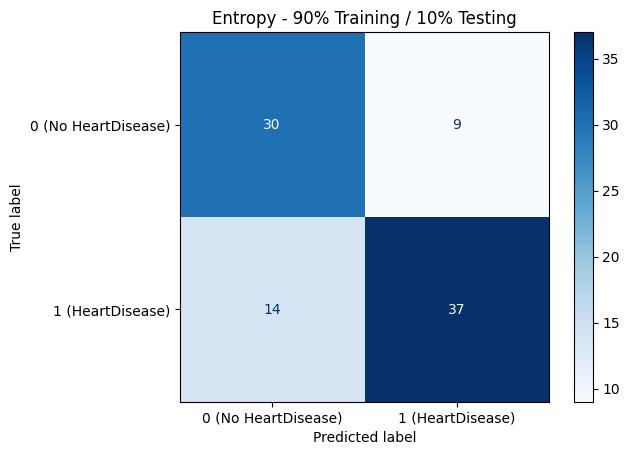

In [40]:
# Entropy (90% Training / 10% Testing)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=1
)

clf_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=1
)

clf_entropy.fit(X_train, y_train)

y_pred = clf_entropy.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["0 (No HeartDisease)", "1 (HeartDisease)"]
)

disp.plot(cmap=plt.cm.Blues)
plt.title("Entropy - 90% Training / 10% Testing")
plt.show()


The model achieved an accuracy of 74.44%, correctly predicting 37 patients with HeartDisease and 30 patients without HeartDisease. However, 14 patients with HeartDisease were incorrectly classified as healthy, while 9 healthy patients were predicted to have HeartDisease.

###Splitting Data into: 80% Training and 20% Testing


Accuracy: 0.75
Confusion Matrix:
[[57 18]
 [27 78]]


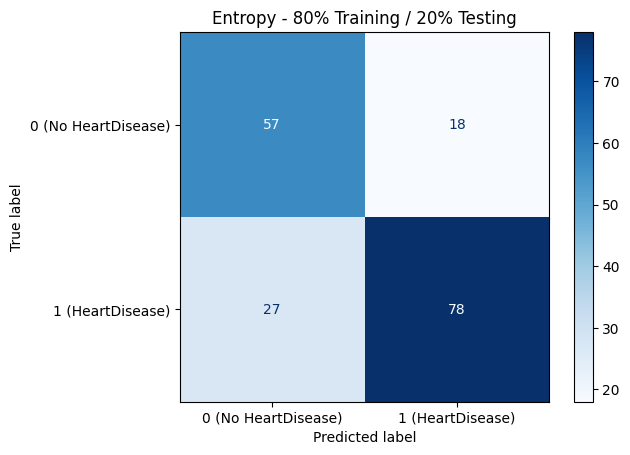

In [39]:
# Entropy (80% Training / 20% Testing)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

clf_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=1
)

clf_entropy.fit(X_train, y_train)

y_pred = clf_entropy.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["0 (No HeartDisease)", "1 (HeartDisease)"]
)

disp.plot(cmap=plt.cm.Blues)
plt.title("Entropy - 80% Training / 20% Testing")
plt.show()

With an accuracy of 75.00%, the model successfully classified 78 patients with HeartDisease and 57 patients without HeartDisease. However, it failed to detect HeartDisease in 27 patients and incorrectly identified 18 healthy patients as having the disease.

###Splitting Data into: 70% Training and 30%Testing


Accuracy: 0.7814814814814814
Confusion Matrix:
[[ 95  25]
 [ 34 116]]


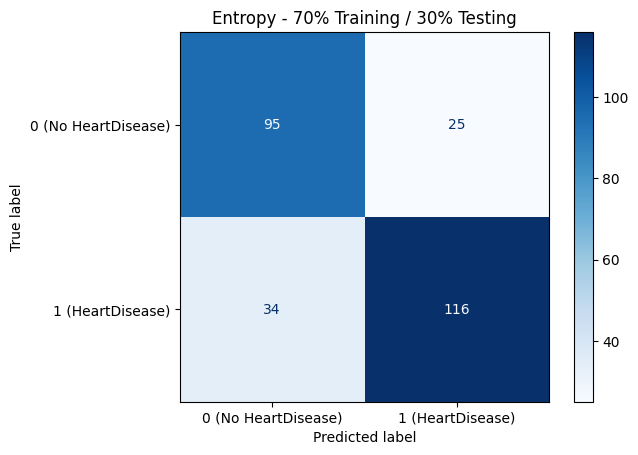

In [38]:

# Entropy (70% Training / 30% Testing)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

clf_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=1
)

clf_entropy.fit(X_train, y_train)

y_pred = clf_entropy.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["0 (No HeartDisease)", "1 (HeartDisease)"]
)

disp.plot(cmap=plt.cm.Blues)
plt.title("Entropy - 70% Training / 30% Testing")
plt.show()


The model reached its highest accuracy of 78.15%, correctly identifying 116 patients with HeartDisease and 95 patients without HeartDisease. However, 34 patients with HeartDisease were misclassified as healthy, and 25 healthy patients were incorrectly predicted to have HeartDisease.

###Entropy Accuracy Comparison


Entropy Accuracy Comparison:


,Train/Test Split,Accuracy
0,90/10,74.44
1,80/20,75.00
2,70/30,78.15


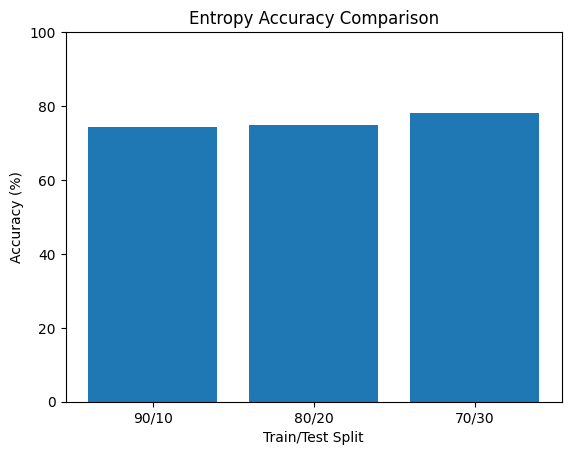

In [ ]:
# Entropy Accuracy Comparison

import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Train/Test Split": ["90/10", "80/20", "70/30"],
    "Accuracy": [74.44, 75.00, 78.15]
})

print("Entropy Accuracy Comparison:")
display(results)

plt.bar(results["Train/Test Split"], results["Accuracy"])

plt.xlabel("Train/Test Split")
plt.ylabel("Accuracy (%)")
plt.title("Entropy Accuracy Comparison")
plt.ylim(0, 100)

plt.show()

Entropy Accuracy Comparison:

The accuracy results show a gradual improvement across the three train-test splits. The model achieved 74.44% accuracy with the 90/10 split, 75.00% with the 80/20 split, and the highest accuracy of 78.15% with the 70/30 split. This indicates that the 70/30 split provided the best classification performance among the tested partitions.

### Decision Tree Visualization – Entropy


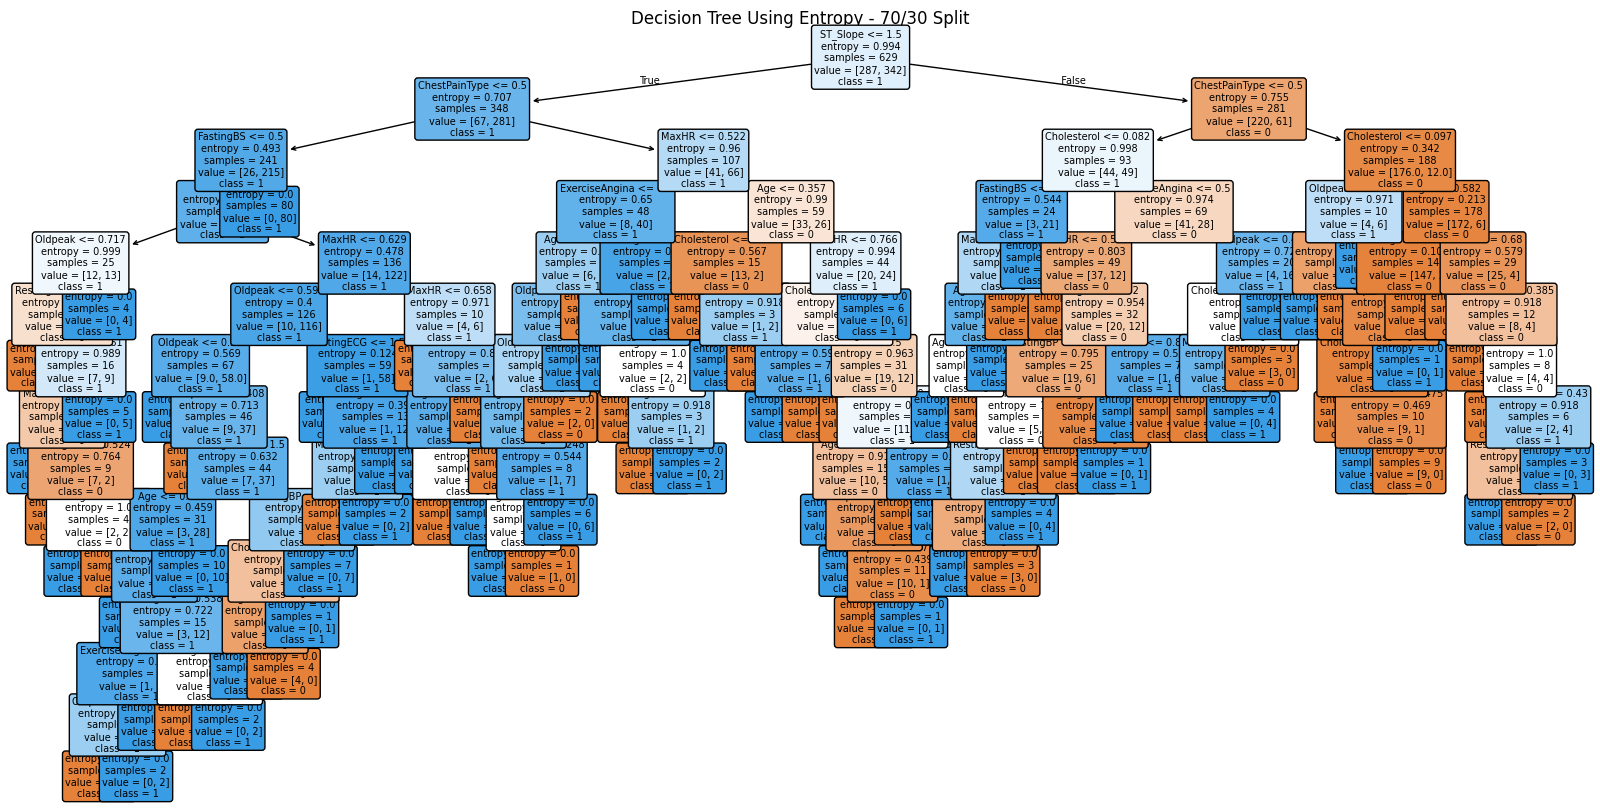

In [ ]:

from sklearn import tree
import matplotlib.pyplot as plt

# Train Decision Tree using Entropy (70/30 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

clf_entropy = DecisionTreeClassifier(
    criterion="entropy",
    random_state=1
)

clf_entropy.fit(X_train, y_train)

# Visualize the Decision Tree
plt.figure(figsize=(20, 10))

tree.plot_tree(
    clf_entropy,
    feature_names=X.columns,
    class_names=[str(c) for c in clf_entropy.classes_],
    filled=True,
    rounded=True,
    fontsize=7
)

plt.title("Decision Tree Using Entropy - 70/30 Split")
plt.show()


The Decision Tree was visualized using Entropy with a 70/30 train-test split, which achieved the highest accuracy of 78.15%. The tree shows how the model splits the data based on feature values to predict HeartDisease. Each node represents a decision based on an attribute, while the leaf nodes represent the predicted classes.

## Gini index:


### Splitting Data into: 90% Training and 10% Test

Confusion Matrix:
[[32  7]
 [15 36]]
Accuracy: 0.7555555555555555


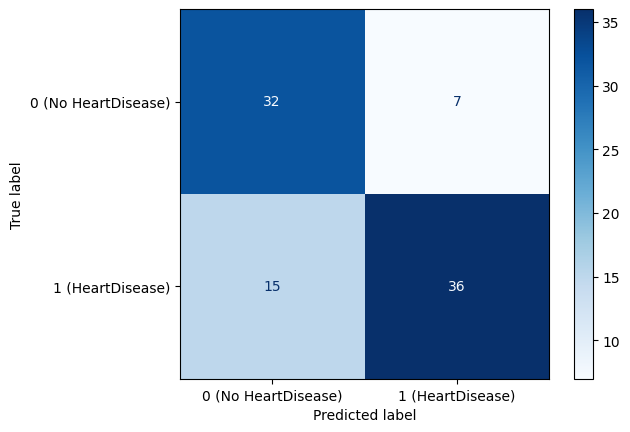

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv(
    "https://raw.githubusercontent.com/saraal1/IT326_Project/main/Dataset/Preprocessed_dataset.csv"
)

# Split the dataset into features and target variable
fn = df.keys().tolist()
fn.remove('HeartDisease')

X = df[fn]
y = df['HeartDisease']

# Split the dataset into training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=1
)

# Initialize the Decision Tree Classifier using Gini Index
clf4 = DecisionTreeClassifier(criterion='gini', random_state=1)

# Fit the classifier to the training data
clf4 = clf4.fit(X_train, y_train)

# Predict labels for the test dataset
y_pred = clf4.predict(X_test)

# Compute and print the confusion matrix
cm4 = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm4)

# Calculate and print accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Define class labels
class_labels = {
    0: '0 (No HeartDisease)',
    1: '1 (HeartDisease)'
}

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm4,
    display_labels=[class_labels[0], class_labels[1]]
)

disp.plot(cmap=plt.cm.Blues)
plt.show()


The Gini-based Decision Tree achieved an accuracy of 75.56% using a 90% training and 10% testing split. The confusion matrix shows that the model correctly classified 32 patients without heart disease and 36 patients with heart disease. However, it incorrectly classified 7 patients without heart disease as having the condition and 15 patients with heart disease as not having the condition.

### Splitting Data into: 80% Training and 20% Test

Confusion Matrix:
[[59 16]
 [27 78]]
Accuracy: 0.7611111111111111


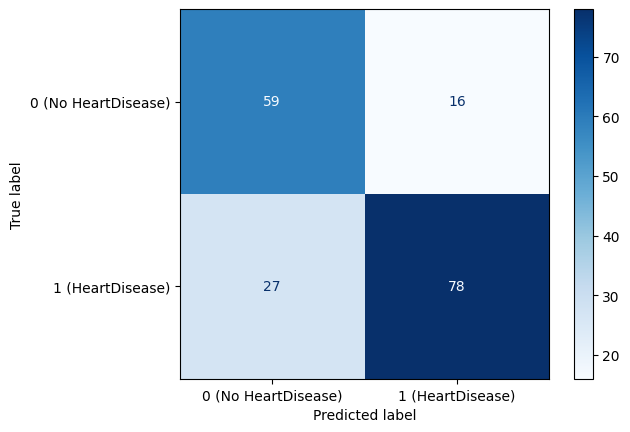

In [ ]:
# Split the dataset into training and testing subsets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

# Initialize the Decision Tree Classifier using Gini Index
clf4 = DecisionTreeClassifier(criterion='gini', random_state=1)

# Fit the classifier to the training data
clf4 = clf4.fit(X_train, y_train)

# Predict labels for the test dataset
y_pred = clf4.predict(X_test)

# Compute and print the confusion matrix
cm4 = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm4)

# Calculate and print accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Define class labels
class_labels = {
    0: '0 (No HeartDisease)',
    1: '1 (HeartDisease)'
}

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm4,
    display_labels=[class_labels[0], class_labels[1]]
)

disp.plot(cmap=plt.cm.Blues)
plt.show()


The Gini-based Decision Tree achieved an accuracy of 76.11% using an 80% training and 20% testing split. The confusion matrix shows that the model correctly classified 59 patients without heart disease and 78 patients with heart disease. However, it incorrectly classified 16 patients without heart disease as having the condition and 27 patients with heart disease as not having the condition.

### Splitting Data into: 70% Training and 30% Test

Confusion Matrix:
[[ 95  25]
 [ 30 120]]
Accuracy: 0.7962962962962963


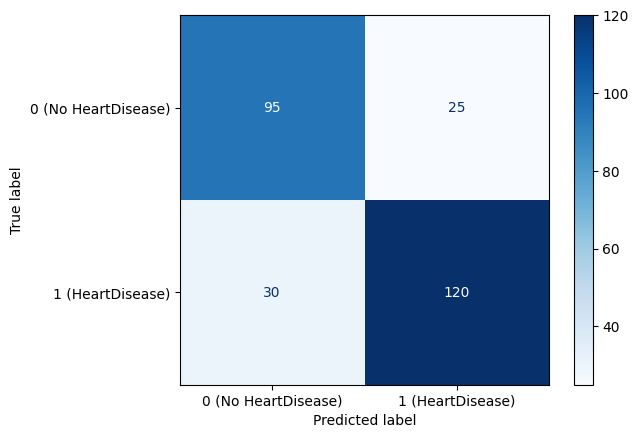

In [ ]:
# Split the dataset into training and testing subsets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

# Initialize the Decision Tree Classifier using Gini Index
clf4 = DecisionTreeClassifier(criterion='gini', random_state=1)

# Fit the classifier to the training data
clf4 = clf4.fit(X_train, y_train)

# Predict labels for the test dataset
y_pred = clf4.predict(X_test)

# Compute and print the confusion matrix
cm4 = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm4)

# Calculate and print accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Define class labels
class_labels = {
    0: '0 (No HeartDisease)',
    1: '1 (HeartDisease)'
}

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm4,
    display_labels=[class_labels[0], class_labels[1]]
)

disp.plot(cmap=plt.cm.Blues)
plt.show()


The Gini-based Decision Tree achieved an accuracy of 79.63% using a 70% training and 30% testing split. The confusion matrix shows that the model correctly classified 95 patients without heart disease and 120 patients with heart disease. However, it incorrectly classified 25 patients without heart disease as having the condition and 30 patients with heart disease as not having the condition.


### Gini Index Results

**Table 2. Accuracy of the Gini-Based Decision Tree Across Different Data Partitions**

| Training / Testing Split | Accuracy |
|---|---:|
| 90% / 10% | 75.56% |
| 80% / 20% | 76.11% |
| 70% / 30% | 79.63% |

The Gini-based Decision Tree achieved its highest accuracy of 79.63% with the 70% training and 30% testing partition. The 80%/20% partition achieved an accuracy of 76.11%, while the 90%/10% partition achieved 75.56%. These results indicate that the model performed best, in terms of accuracy, with the 70%/30% partition among the three tested splits.
